# 03 — Machine Report Statements, Lead Reversals & Hardware Filter Confounders

In MIMIC-IV-ECG, `report_0..report_17` store **machine-generated** diagnostic & technical statements (not human-validated ground truth), while `bandwidth` and `filtering` record the cart's analog/digital passband.

This notebook audits:
1. Top machine diagnostic statements across all `800,035` studies + empty-report rate.
2. Explicit technical defect warnings embedded in reports (**`lead reversal`**, **`poor data quality`**, **`artifact`**, **`pacemaker`**, **`pediatric`**).
3. **Hardware Filter Confounding**: Checking `bandwidth` (`0.005–150 Hz`, `0.0005–150 Hz`, `0.05–150 Hz`) and `filtering` (`60 Hz notch`, `<not specified>`, `Baseline filter`, **`50 Hz notch` in Boston USA!**) against `Abnormal ECG` / `Normal ECG` rates (shortcut-learning risk!).

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import wfdb

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})

_cwd = Path.cwd().resolve()
for _candidate in [_cwd, _cwd.parent, _cwd.parent.parent]:
    if (_candidate / "mimic_iv_ecg" / "quality" / "error_labels.csv.gz").exists():
        REPO_ROOT = _candidate
        break
else:
    raise FileNotFoundError(f"Could not locate mimic_iv_ecg/quality/error_labels.csv.gz from {_cwd}")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from mimic_iv_ecg import MIMICIVECGDataset

MIMIC_DIR = REPO_ROOT / "mimic_iv_ecg"
DATA_DIR = MIMIC_DIR / "data"
QUALITY_DIR = MIMIC_DIR / "quality"
LEADS = MIMICIVECGDataset.LEADS

rep_cols = [f"report_{i}" for i in range(18)]
mm = pd.read_csv(DATA_DIR / "machine_measurements.csv", usecols=["bandwidth", "filtering"] + rep_cols, low_memory=False)
err_df = pd.read_csv(QUALITY_DIR / "error_labels.csv.gz", index_col="study_id")

# Top 20 individual report statements across report_0..report_17
stacked = mm[rep_cols].stack().astype(str).str.strip()
stacked = stacked[stacked != ""]
top20_stmts = stacked.value_counts().head(20)
print(f"Total non-empty report lines across 800,035 studies: {len(stacked):,} (avg {len(stacked)/len(mm):.2f} lines/study)")

# Check Abnormal vs Normal ECG rate across filtering & bandwidth settings
all_rep_low = mm[rep_cols].fillna("").agg(" | ".join, axis=1).str.lower()
mm["is_normal_ecg"] = all_rep_low.str.contains("normal ecg", regex=False)
mm["is_abnormal_ecg"] = all_rep_low.str.contains("abnormal ecg", regex=False)
mm["is_afib"] = all_rep_low.str.contains("atrial fibrillation", regex=False)

filt_audit = mm.groupby(mm["filtering"].fillna("<NaN>")).agg(
    n_studies=("is_normal_ecg", "size"),
    pct_normal=("is_normal_ecg", lambda s: round(s.mean() * 100, 2)),
    pct_abnormal=("is_abnormal_ecg", lambda s: round(s.mean() * 100, 2)),
    pct_afib=("is_afib", lambda s: round(s.mean() * 100, 2)),
).sort_values("n_studies", ascending=False)
print("\n=== Hardware Filtering Setting × Clinical Statement Rate (Confounder Check) ===")
display(filt_audit)

bw_audit = mm.groupby(mm["bandwidth"].fillna("<NaN>")).agg(
    n_studies=("is_normal_ecg", "size"),
    pct_normal=("is_normal_ecg", lambda s: round(s.mean() * 100, 2)),
    pct_abnormal=("is_abnormal_ecg", lambda s: round(s.mean() * 100, 2)),
    pct_afib=("is_afib", lambda s: round(s.mean() * 100, 2)),
).sort_values("n_studies", ascending=False)
display(bw_audit)

Total non-empty report lines across 800,035 studies: 14,400,630 (avg 18.00 lines/study)



=== Hardware Filtering Setting × Clinical Statement Rate (Confounder Check) ===


,n_studies,pct_normal,pct_abnormal,pct_afib
filtering,,,,
60 Hz notch Baseline filter,677415,74.54,51.96,10.54
<not specified>,107398,0.00,0.00,7.37
Baseline filter,12505,71.56,44.03,7.96
50 Hz notch Baseline filter,2717,77.77,67.65,17.59


,n_studies,pct_normal,pct_abnormal,pct_afib
bandwidth,,,,
0.005-150 Hz,637197,74.50,52.0,10.46
0.0005-150 Hz,111330,2.84,2.6,7.68
0.05-150 Hz,51508,74.04,48.7,10.78


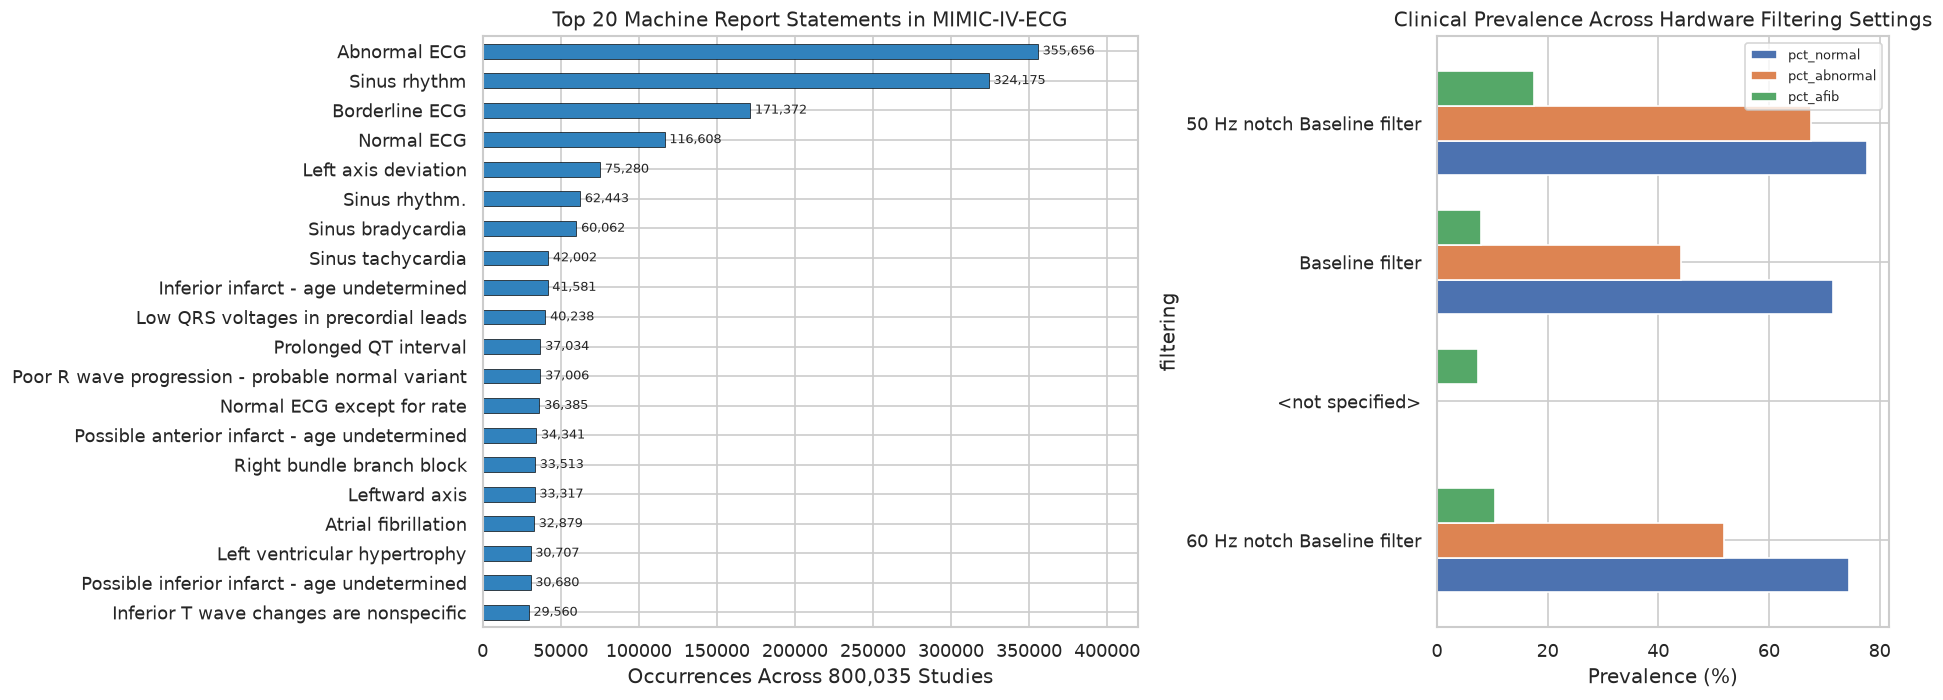

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.0), gridspec_kw={"width_ratios": [1.45, 1]})

top20_stmts.sort_values().plot(kind="barh", ax=axes[0], color="#3182bd", edgecolor="black", lw=0.4)
axes[0].set_xlabel("Occurrences Across 800,035 Studies")
axes[0].set_title("Top 20 Machine Report Statements in MIMIC-IV-ECG")
for i, v in enumerate(top20_stmts.sort_values().values):
    axes[0].text(v + 3000, i, f"{v:,}", va="center", fontsize=7.8)
axes[0].set_xlim(0, top20_stmts.max() * 1.18)

filt_audit[["pct_normal", "pct_abnormal", "pct_afib"]].plot(kind="barh", ax=axes[1], width=0.75)
axes[1].set_xlabel("Prevalence (%)")
axes[1].set_title("Clinical Prevalence Across Hardware Filtering Settings")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()